# Basic ShopSphere EDA

This notebook uses the cleaned CSV files in the `silver` folder. It makes seven simple charts to summarize orders, sales, and customers.

Run the notebook with the project folder as the working directory. The charts use basic pandas plotting; no chart colors or styling are set.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("silver/orders.csv", parse_dates=["order_date"])
items = pd.read_csv("silver/order_items.csv")
products = pd.read_csv("silver/products.csv")
customers = pd.read_csv("silver/customers.csv")

print("Orders:", len(orders))
print("Order lines:", len(items))
print("Products:", len(products))
print("Customers:", len(customers))

valid_orders = orders[orders["order_status"].isin(["Completed", "Returned"])]
sales = items.merge(valid_orders[["order_id", "channel"]], on="order_id")
sales = sales.merge(products[["product_id", "category"]], on="product_id")

Orders: 320
Order lines: 769
Products: 70
Customers: 158


## 1. Orders by status

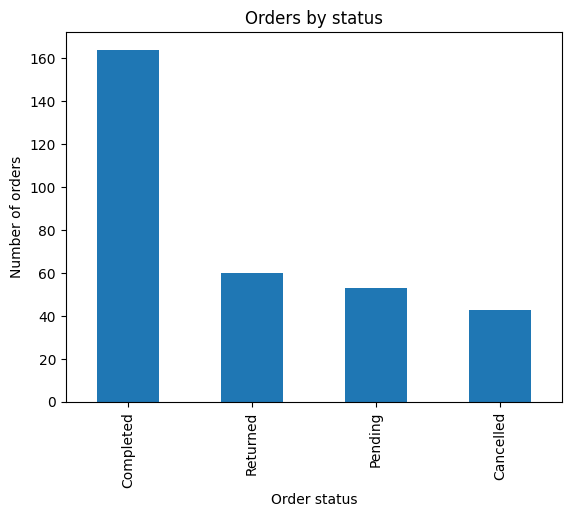

In [2]:
orders["order_status"].value_counts().plot(kind="bar", title="Orders by status")
plt.xlabel("Order status")
plt.ylabel("Number of orders")
plt.show()

## 2. Orders over time

## 3. Gross sales by product category

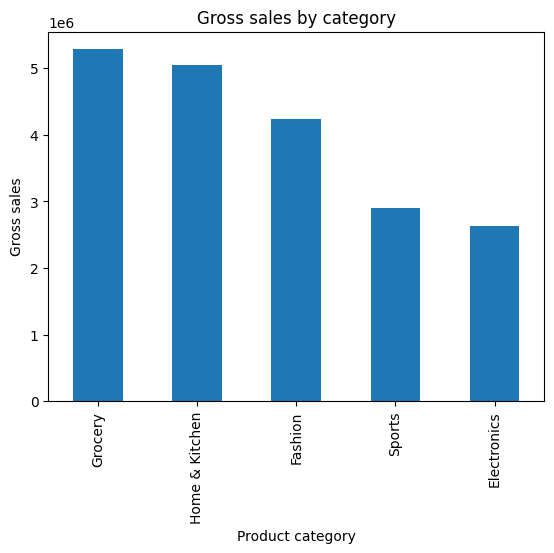

In [4]:
sales_by_category = sales.groupby("category")["line_total"].sum().sort_values(ascending=False)
sales_by_category.plot(kind="bar", title="Gross sales by category")
plt.xlabel("Product category")
plt.ylabel("Gross sales")
plt.show()

## 4. Order value distribution

## 5. Order values by sales channel

## 6. Customers by segment

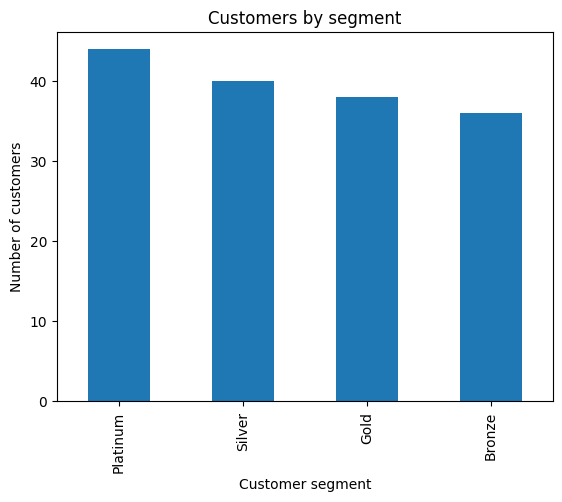

In [7]:
customers["customer_segment"].value_counts().plot(kind="bar", title="Customers by segment")
plt.xlabel("Customer segment")
plt.ylabel("Number of customers")
plt.show()

## 7. Units sold by product category

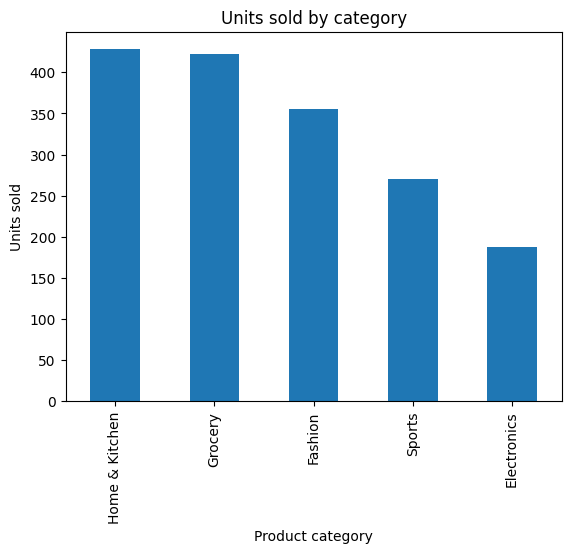

In [8]:
units_by_category = sales.groupby("category")["quantity"].sum().sort_values(ascending=False)
units_by_category.plot(kind="bar", title="Units sold by category")
plt.xlabel("Product category")
plt.ylabel("Units sold")
plt.show()

## Payment data: one-variable analysis

Payment status and method are categories, so bar charts show their counts. Histograms need numbers, so the two histograms show payment amounts grouped by status and by payment method.

In [9]:
payments = pd.read_csv('silver/payments.csv')
payments['amount'] = pd.to_numeric(payments['amount'], errors='coerce')

### 8. Payment count by status

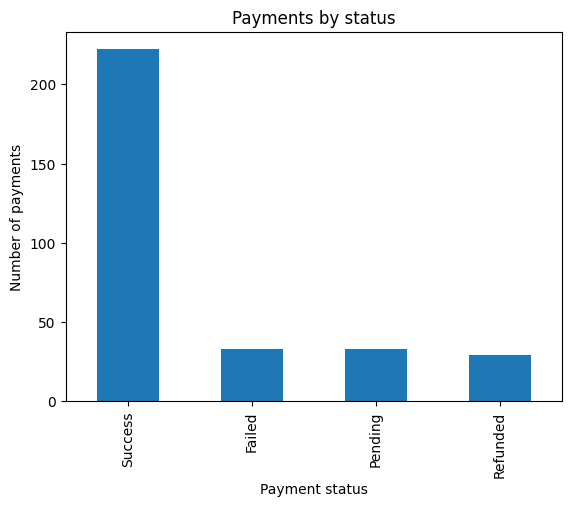

In [10]:
payments['payment_status'].value_counts().plot(kind='bar', title='Payments by status')
plt.xlabel('Payment status')
plt.ylabel('Number of payments')
plt.show()

### 9. Payment amount by status

### 10. Payment count by method

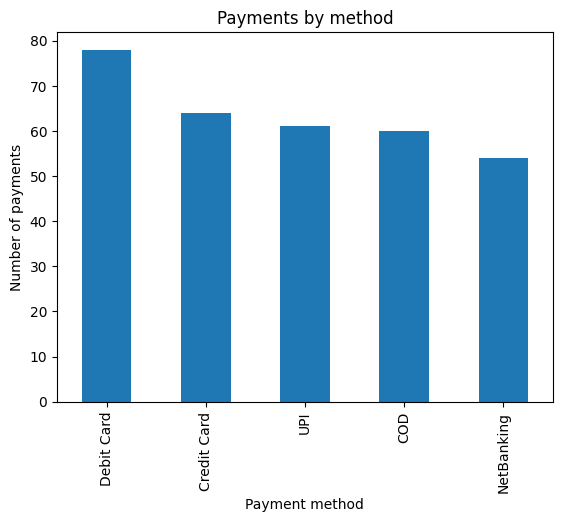

In [12]:
payments['payment_method'].value_counts().plot(kind='bar', title='Payments by method')
plt.xlabel('Payment method')
plt.ylabel('Number of payments')
plt.show()

### 11. Payment amount by method